In [1]:
import matplotlib.pyplot as plt
import time
import torch
import numpy as np
from sympy.codegen.rewriting import Optimization
from tqdm import tqdm
from tqdm.notebook import tqdm
import pandas as pd
import torch
import os
from datetime import datetime
import sys
import json
from tqdm import trange
from functools import partial

In [2]:
# Check if running in Google Colab
if 'google.colab' in str(get_ipython()):
    import getpass
    !pip install flow_matching

    # Prompt the user for their GitHub personal access token (hidden input)
    # token = getpass.getpass("Enter your GitHub personal access token: ")
    token=os.environ["GITHUB_TOKEN"]
    repo_url = f"https://{token}@github.com/orineo1/GlobalConditional.git"
    repo_name = "GlobalConditional"

    # Clone the repository
    if not os.path.exists(repo_name):
        !git clone {repo_url}
    branch_name = "AddingSuperposition"
    !cd {repo_name} && git checkout {branch_name}

    # Add the repository to Python path
    sys.path.append(f"/content/{repo_name}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.7/48.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 101.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 89.6 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstallin

In [3]:
import importlib
import Diffusion
import DiffusionGeneral
import superposition_utils

import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)
importlib.reload(superposition_utils)
importlib.reload(DiffusionGeneral)



<module 'DiffusionGeneral' from '/content/GlobalConditional/DiffusionGeneral.py'>

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


# 2D cond on 1D

In [5]:
mu_list = [torch.tensor([-5,5],dtype=torch.float64),
           torch.tensor([-5,-5],dtype=torch.float64),
           torch.tensor([5, 3],dtype=torch.float64),
           torch.tensor([5,-1],dtype=torch.float64),
           torch.tensor([0, -3],dtype=torch.float64),
           torch.tensor([-2,4 ],dtype=torch.float64),
           torch.tensor([-2,-3 ],dtype=torch.float64),
           torch.tensor([ 1,2],dtype=torch.float64),
           torch.tensor([-7,1],dtype=torch.float64),
           torch.tensor([7,5],dtype=torch.float64),
           torch.tensor([0,-5],dtype=torch.float64)

           ]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[0.5,0.25],[0.12,0.2]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)

## Target
x_optim=x_star=torch.tensor([-5])
mu_temp, Sigma_temp =dist_utils.compute_conditionals(mu_list, Sigma_list, x_optim)
temp_alpha = dist_utils.compute_alpha(mu_list, Sigma_list, alpha, x_optim)
mog_means, mog_variances, weights= dist_utils.filter_and_normalize(mu_temp, Sigma_temp, temp_alpha, threshold=0.01)


/content/GlobalConditional/dist_utils.py:412: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:3725.)
  exponent = -0.5 * diff.T @ Sigma_22_inv @ diff


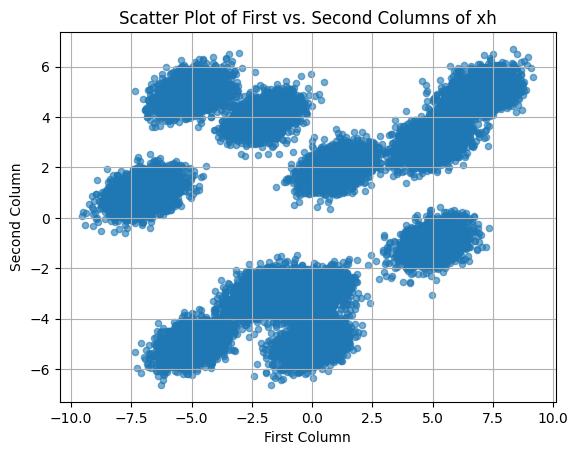

In [6]:
X = dist_utils.generate_mog_samples(25_000, mu_list, Sigma_list, alpha).float().to(device)
# Convert to numpy
xh_cpu = X.detach().cpu().numpy()

# Scatter plot of first column vs. second column
plt.scatter(xh_cpu[:, 0], xh_cpu[:, 1], alpha=0.6, s=20)
plt.title("Scatter Plot of First vs. Second Columns of xh")
plt.xlabel("First Column")
plt.ylabel("Second Column")
plt.grid(True)
plt.show()

## Parameters for tests

In [7]:
## NN
nblocks=3
nunits=128
nepochs=1
batch_size=512

## Diffusion
diffusion_steps=100

## Optimization
n_attemp_optim=1
nsamples_in_optim_for_mmd=100

## SuperPosition

### Train

In [8]:
point_l = [[int(p[1]), int(p[0])] for p in mu_list]
mu_list_super = [torch.tensor(p, dtype=torch.float64) for p in point_l]
Sigma_list_super = [s[torch.tensor([1, 0])][:, torch.tensor([1, 0])] for s in Sigma_list]# [.T for sigma in Sigma_list]

condition_on=1
nfeatures= X.shape[1]

model_cond_diff =DiffusionGeneral.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=True,condition_on=condition_on,diffusion_steps=diffusion_steps)
model_cond_diff.train_model( data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list_super, S=Sigma_list_super, beta=alpha, kernel_func=None),dataloader=None, num_iterations=nepochs)


100%|██████████| 1/1 [00:00<00:00,  3.95it/s, loss=6.23]


### Optimize

In [9]:
n_sample=n_attemp_optim
cond1= torch.tensor([5.],device=device)
cond2= torch.tensor([-5.],device=device)


cond_l= [cond1,cond2]



start_time = time.time()
x_gen_iso,_=  superposition_utils.generate_isosurface_samples(model_cond_diff, cond_l=cond_l,bs=n_sample,device=device)
end_time = time.time()
superposition_times = [end_time - start_time] *n_attemp_optim

X_gen_np = x_gen_iso[:, -1, :].detach().cpu().numpy()




  0%|          | 0/1000 [00:00<?, ?it/s]

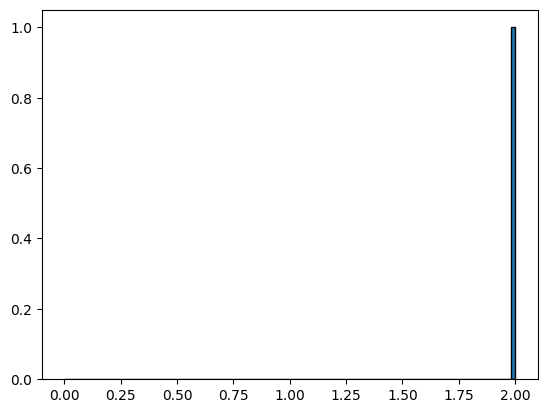

In [10]:
best_x_t_superposition_list=[]
l1_distance_superposition_list=[]
for optimal_x in  X_gen_np[:,1]:
    l1_distance = dist_utils.warpper_L1_distance(torch.tensor([optimal_x]),mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_superposition_list.append(l1_distance )
    best_x_t_superposition_list.append(optimal_x)


plt.hist(l1_distance_superposition_list,  edgecolor='black',range=(0,2),bins=100,)
plt.show()

In [11]:
print(best_x_t_superposition_list)
print(l1_distance_superposition_list)



[np.float32(-360.63745)]
[tensor(1.9992, dtype=torch.float64)]


## Consistency Models

In [12]:
B, C = X.shape
nfeatures = C - condition_on

Cos_model = ConsistencyModel(nfeatures=nfeatures, condition_on=condition_on, nunits=128)
Cos_model.train_model(X=None
                      , nepochs=nepochs
                      ,batch_size=256, device= "cpu", condition=condition_on,
                      data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None),
                      )

loss: 0.001935, mu: 0.9993: 100%|██████████| 1/1 [00:00<00:00, 21.58it/s]


## LGD

### Train

In [13]:
## LGD
# init a model, train
X = dist_utils.generate_mog_samples(1_000, mu_list, Sigma_list, alpha).float().to(device)
nfeatures = X.shape[1]
condition_on = mu_list[0].shape[0] - mog_means[0].shape[0]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=True,
                                      condition_on=condition_on, diffusion_steps=diffusion_steps)
losses = model_cond.train_model(X,
                                data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None),
                                nepochs=nepochs, batch_size=batch_size, condition_on=condition_on)

loss: 11.991646: 100%|██████████| 1/1 [00:00<00:00, 15.74it/s]


In [14]:
# init a model, train
X_for_cond_only = X[:, :model_cond.condition_on]
nfeatures = X_for_cond_only.shape[1]


model_uncond=Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=nblocks, nunits=nunits, condition=False,diffusion_steps=diffusion_steps)
losses = model_uncond.train_model(X_for_cond_only,
                                  data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha,kernel_func=lambda X: X[:, :model_cond.condition_on]),
                                  nepochs=nepochs
, batch_size=batch_size, condition_on=condition_on)


loss: 32.473335: 100%|██████████| 1/1 [00:00<00:00, 18.28it/s]


### Optimize

#### Regular

100%|██████████| 1/1 [03:04<00:00, 184.62s/it]

[tensor([[-5.8495]])]
[tensor(0.6338, dtype=torch.float64)]


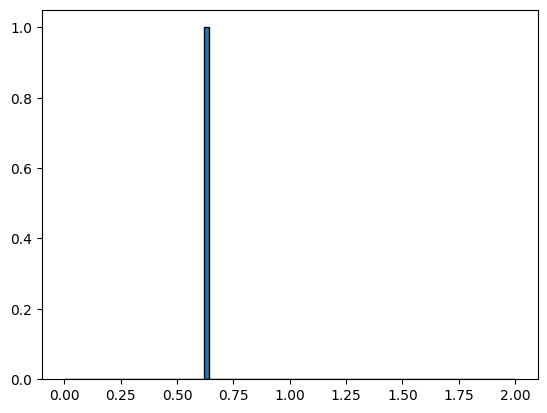

In [15]:
best_x_t_LGD_list=[]
l1_distance_LGD_list=[]
lgd_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    best_x_t, best_x_0_cont_xt_hat, best_mmd_loss = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights, mu_list, Sigma_list, alpha, nsamples=nsamples_in_optim_for_mmd, loss="MMD", device=device)
    end_time = time.time()
    lgd_times.append(end_time - start_time)

    best_x_t_LGD_list.append(best_x_t)
    l1_distance = dist_utils.warpper_L1_distance(best_x_t, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_LGD_list.append(l1_distance)

print(best_x_t_LGD_list)
print(l1_distance_LGD_list)

plt.hist(l1_distance_LGD_list,  edgecolor='black',range=(0,2),bins=100,)
plt.show()

### Optimize

#### CM

100%|██████████| 1/1 [00:16<00:00, 16.60s/it]

[tensor([[4.0188]])]
[tensor(1.9962, dtype=torch.float64)]


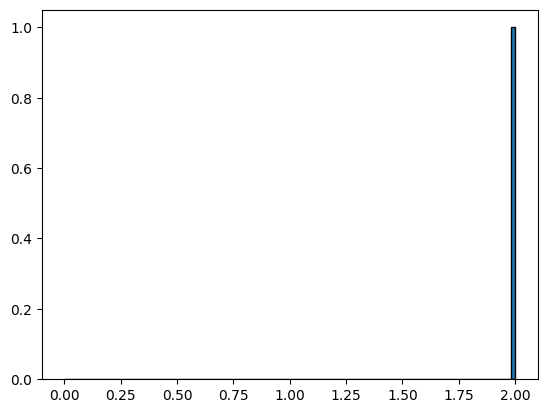

In [16]:
best_x_t_LGD_CM_list=[]
l1_distance_LGD_CM_list=[]
# For LGD_CM timing
lgd_cm_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    best_x_t, best_x_0_cont_xt_hat, best_mmd_loss = Optimization.optimize_LGD(model_uncond, Cos_model, mog_means, mog_variances, weights, mu_list, Sigma_list, alpha, nsamples=nsamples_in_optim_for_mmd, loss="MMD", device=device, CM=True, FLAG=False)
    end_time = time.time()
    lgd_cm_times.append(end_time - start_time)

    best_x_t_LGD_CM_list.append(best_x_t)
    l1_distance = dist_utils.warpper_L1_distance(best_x_t, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_LGD_CM_list.append(l1_distance)

print(best_x_t_LGD_CM_list)
print(l1_distance_LGD_CM_list)


plt.hist(l1_distance_LGD_CM_list,  edgecolor='black',range=(0,2),bins=100,)
plt.show()

## Flow

### Train

In [17]:
input_dim =mog_means[0].shape[0]
y_dim = mu_list[0].shape[0]-mog_means[0].shape[0]
hidden_dim = nunits
depth = nblocks


In [18]:

vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=batch_size, X=X, nepochs=nepochs,
                                                        data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None)
                     )


loss: 25.099496: 100%|██████████| 1/1 [00:00<00:00, 18.57it/s]


In [19]:
first_column_x=X[:,:y_dim]#print()#print()
input_dim = first_column_x.shape[1]
vf_X = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=0,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_X.train_FM(lr=0.001, batch_size=batch_size, X=first_column_x, nepochs=nepochs,
                                                                      data_generator=partial(dist_utils.generate_mog_samples, xi=mu_list, S=Sigma_list, beta=alpha, kernel_func=None))


loss: 27.128146: 100%|██████████| 1/1 [00:00<00:00, 19.89it/s]


### Optimize

#### Regular

In [20]:
best_x_t_dflow_list=[]
l1_distance_dflow_list=[]
dflow_times = []
for i in trange(n_attemp_optim):
    start_time = time.time()
    x_optim, loss = Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100, FLAG=False, n_sample=nsamples_in_optim_for_mmd, loss_method="MMD", line_search_fn="strong_wolfe")
    end_time = time.time()
    dflow_times.append(end_time - start_time)

    best_x_t_dflow_list.append(x_optim)

    l1_distance = dist_utils.warpper_L1_distance(x_optim, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
    l1_distance_dflow_list.append(l1_distance)



100%|██████████| 1/1 [00:03<00:00,  3.91s/it]


In [21]:
print(best_x_t_dflow_list)
print(l1_distance_dflow_list)

[tensor([[-0.2294]], grad_fn=<SelectBackward0>)]
[tensor(1.1066, dtype=torch.float64, grad_fn=<DivBackward1>)]


## Summary

/tmp/ipython-input-22-4120974936.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


[[array(1.1066451)], [array(1.99920124)], [array(0.63377637)], [array(1.99619971)]]


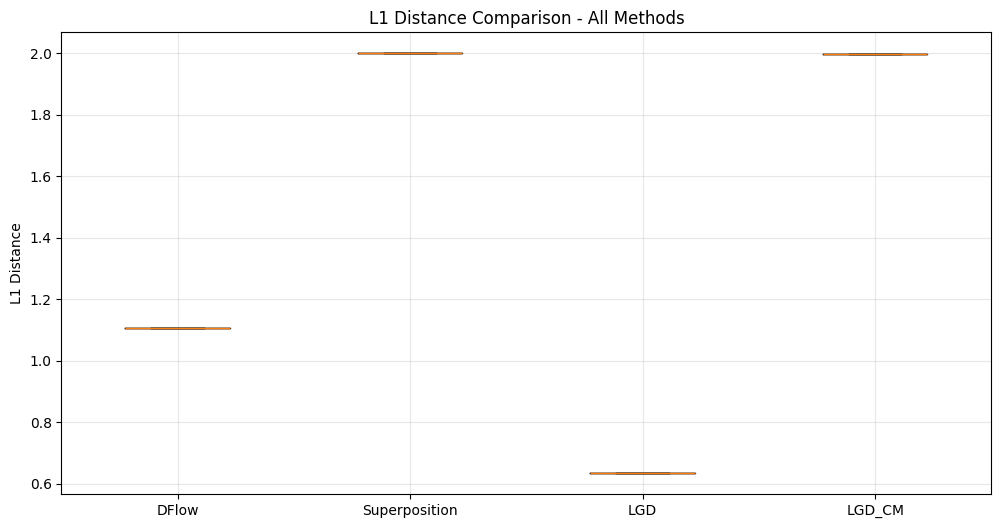

In [22]:
import matplotlib.pyplot as plt

# change
# Create boxplot for all four distance lists
data = [l1_distance_dflow_list, l1_distance_superposition_list, l1_distance_LGD_list, l1_distance_LGD_CM_list]
data = [[l.detach().numpy() for l in dist_list]  for dist_list in  data]
print(data)
labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']

plt.figure(figsize=(12, 6))
plt.boxplot(data, labels=labels)
plt.ylabel('L1 Distance')
plt.title('L1 Distance Comparison - All Methods')
plt.grid(True, alpha=0.3)
plt.show()
# changed

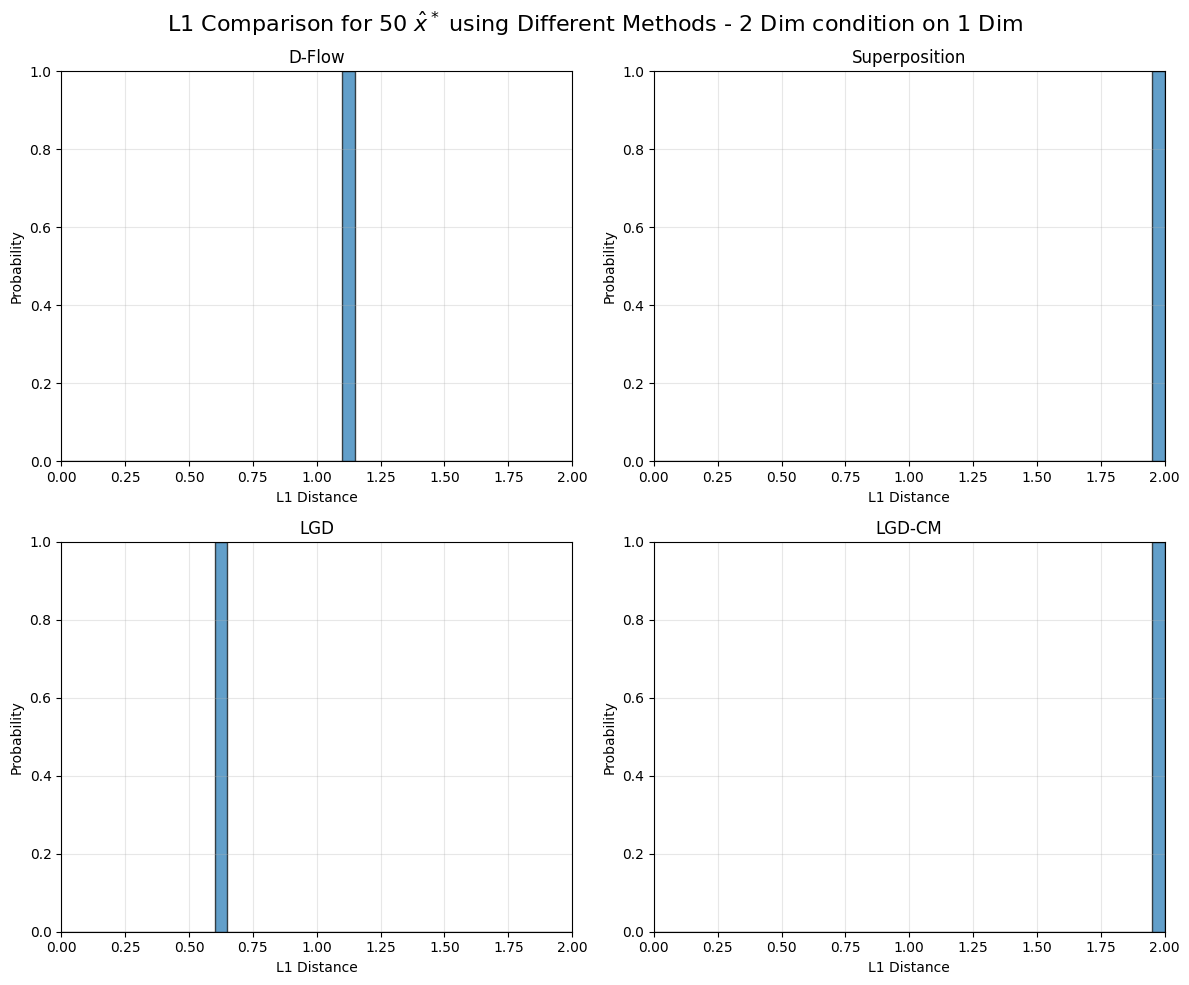

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Your data
data = [l1_distance_dflow_list, l1_distance_superposition_list, l1_distance_LGD_list, l1_distance_LGD_CM_list]
data = [[l.detach().numpy() for l in dist_list] for dist_list in data]

# Method names for titles
method_names = ['D-Flow', 'Superposition', 'LGD', 'LGD-CM']

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()  # Make it easier to iterate

# Plot histograms
for i, (distances, method_name) in enumerate(zip(data, method_names)):
    # Flatten the list of arrays if needed
    flat_distances = np.concatenate([np.array(d).flatten() for d in distances])

    # Create bins every 0.05 from 0 to 2
    bins = np.arange(0, 2.05, 0.05)  # 0.05 to include 2.0

    # Calculate histogram with probability (weights sum to 1)
    weights = np.ones_like(flat_distances) / len(flat_distances)
    axes[i].hist(flat_distances, bins=bins, alpha=0.7, edgecolor='black', weights=weights)
    axes[i].set_title(f'{method_name}')
    axes[i].set_xlabel('L1 Distance')
    axes[i].set_ylabel('Probability')
    axes[i].set_xlim(0, 2)
    axes[i].set_ylim(0, 1)
    axes[i].grid(True, alpha=0.3)



# Add main title
fig.suptitle(r'L1 Comparison for 50 $\hat{x}^*$ using Different Methods - 2 Dim condition on 1 Dim', fontsize=16)

plt.tight_layout()
plt.show()


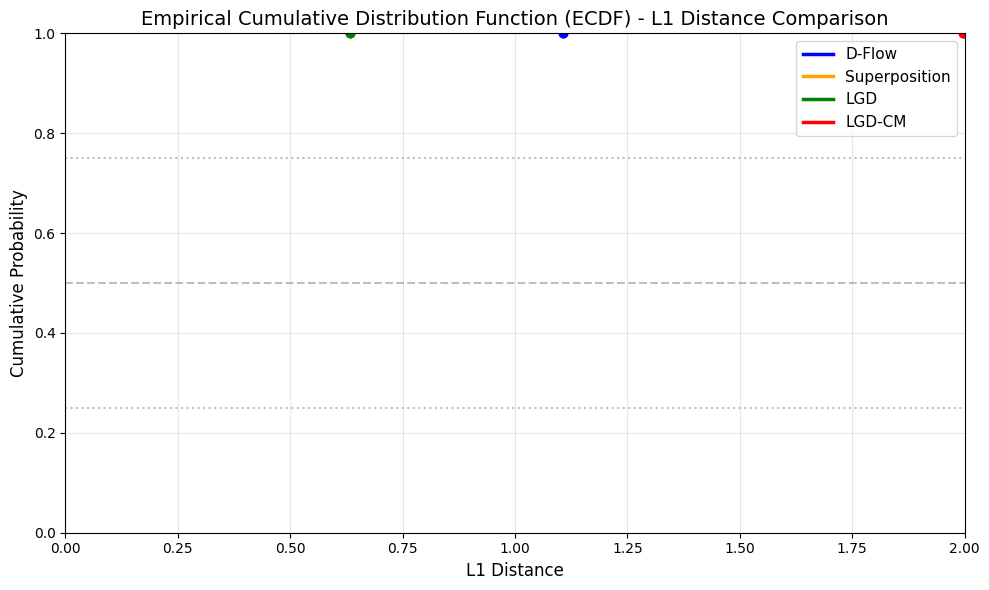

In [24]:
# Create ECDF plot
plt.figure(figsize=(10, 6))
colors = ['blue', 'orange', 'green', 'red']

for i, (distances, method_name, color) in enumerate(zip(data, method_names, colors)):
    # Flatten the list of arrays if needed
    flat_distances = np.concatenate([np.array(d).flatten() for d in distances])

    # Sort the data
    sorted_data = np.sort(flat_distances)
    # Calculate ECDF values
    ecdf_y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)

    plt.plot(sorted_data, ecdf_y, label=method_name, color=color, linewidth=2.5)

    # Add markers at quartiles for better readability
    quartiles = [0.25, 0.5, 0.75]
    for q in quartiles:
        idx = int(q * len(sorted_data))
        plt.plot(sorted_data[idx], ecdf_y[idx], 'o', color=color, markersize=6)

plt.xlabel('L1 Distance', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Empirical Cumulative Distribution Function (ECDF) - L1 Distance Comparison', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0, 2)
plt.ylim(0, 1)

# Add reference lines
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Median (50%)')
plt.axhline(y=0.25, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=0.75, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

['DFlow', 'Superposition', 'LGD', 'LGD_CM']


/tmp/ipython-input-25-1336545245.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(time_data, labels=time_labels)


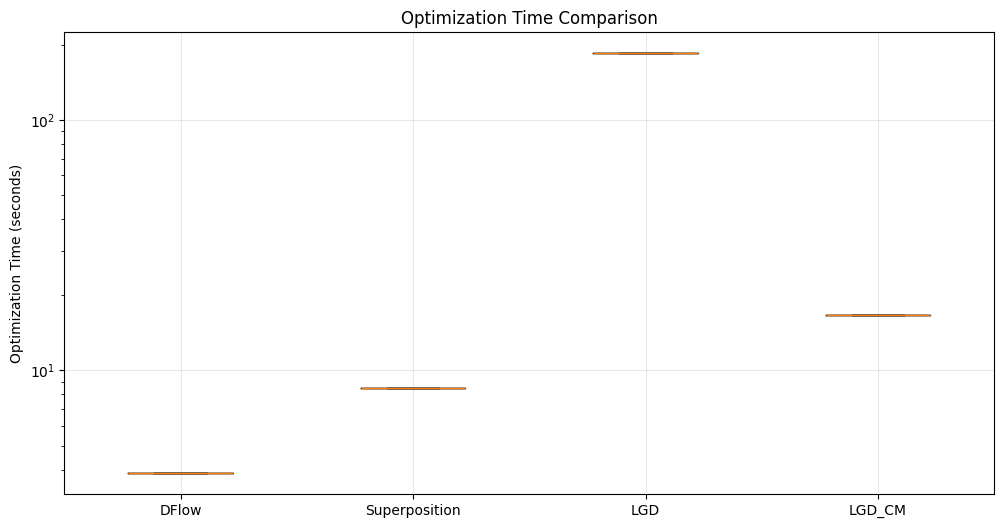

In [25]:
# Plot optimization times
time_data = [dflow_times, superposition_times, lgd_times, lgd_cm_times]
time_labels = ['DFlow', 'Superposition', 'LGD', 'LGD_CM']
print(time_labels)
plt.figure(figsize=(12, 6))
plt.boxplot(time_data, labels=time_labels)
plt.ylabel('Optimization Time (seconds)')
plt.title('Optimization Time Comparison')
plt.yscale('log')  # Add log scale to y-axis
plt.grid(True, alpha=0.3)
plt.show()





In [26]:
import torch
import numpy as np
import pandas as pd
import pickle

def to_numpy(x):
    """Convert tensor/numpy to numpy array - handles gradients properly"""
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    return np.array(x)

def to_list(x_list):
    """Convert list of tensors/numpy to list of floats - fixed gradient handling"""
    result = []
    for x in x_list:
        x_np = to_numpy(x)  # Use our safe to_numpy function
        if x_np.size == 1:
            result.append(float(x_np))
        else:
            result.append(x_np.tolist())
    return result

def save_model_safely(model, model_name):
    """Safely save a model - handles different model types and pickling issues"""
    if model is None:
        return None

    try:
        # Test if the model can be pickled
        pickle.dumps(model)

        # If pickling works, save the full model
        if hasattr(model, 'state_dict'):
            model_data = {
                'type': 'pytorch_model',
                'state_dict': model.state_dict(),
                'model_class': model.__class__.__name__,
                'model_object': model,
                'picklable': True
            }
        else:
            model_data = {
                'type': 'other_model',
                'model_object': model,
                'model_class': model.__class__.__name__,
                'picklable': True
            }

        return model_data

    except Exception as e:
        # If pickling fails, save only the state_dict for PyTorch models
        try:
            if hasattr(model, 'state_dict'):
                model_data = {
                    'type': 'pytorch_model',
                    'state_dict': model.state_dict(),
                    'model_class': model.__class__.__name__,
                    'model_object': None,  # Can't pickle the full model
                    'picklable': False,
                    'error': str(e)
                }
                return model_data
            else:
                # For non-PyTorch models that can't be pickled, save basic info
                model_data = {
                    'type': 'unpicklable_model',
                    'model_class': model.__class__.__name__,
                    'model_object': None,
                    'picklable': False,
                    'error': str(e)
                }
                return model_data
        except Exception as e2:
            return {
                'type': 'failed_model',
                'model_class': 'unknown',
                'picklable': False,
                'error': f"Complete failure: {str(e2)}"
            }

# Store all data including models
data = {
    'x_star': to_numpy(x_star).tolist(),

    # Results (converted to lists)
    'results': {
        'DFlow': [to_numpy(x).tolist() for x in best_x_t_dflow_list],
        'Superposition': [to_numpy(x).tolist() for x in best_x_t_superposition_list],
        'LGD': [to_numpy(x).tolist() for x in best_x_t_LGD_list],
        'LGD_CM': [to_numpy(x).tolist() for x in best_x_t_LGD_CM_list]
    },

    # Pre-calculated distances (converted to simple lists)
    'distances': {
        'DFlow_L1': to_list(l1_distance_dflow_list),
        'Superposition_L1': to_list(l1_distance_superposition_list),
        'LGD_L1': to_list(l1_distance_LGD_list),
        'LGD_CM_L1': to_list(l1_distance_LGD_CM_list),
    },

    # Times
    'times': {
        'DFlow': float(dflow_times[0]) if 'dflow_times' in globals() and len(dflow_times) > 0 else None,
        'Superposition': float(superposition_times[0]) if 'superposition_times' in globals() and len(superposition_times) > 0 else None,
        'LGD': float(lgd_times[0]) if 'lgd_times' in globals() and len(lgd_times) > 0 else None,
        'LGD_CM': float(lgd_cm_times[0]) if 'lgd_cm_times' in globals() and len(lgd_cm_times) > 0 else None
    },

    # 🔥 MODELS - Save all your models here
    'models': {}
}

print("💾 SAVING MODELS...")

# Save all your models
models_to_save = {
    'superposition_cond_diff': model_cond_diff if 'model_cond_diff' in globals() else None,
    'consistency_model': Cos_model if 'Cos_model' in globals() else None,
    'LGD_conditional': model_cond if 'model_cond' in globals() else None,
    'LGD_unconditional': model_uncond if 'model_uncond' in globals() else None,
    # 'flow_conditional': vf_y_cond_x if 'vf_y_cond_x' in globals() else None,
    # 'flow_unconditional': vf_X if 'vf_X' in globals() else None
}

for model_name, model in models_to_save.items():
    data['models'][model_name] = save_model_safely(model, model_name)

# Calculate additional L1/L2 distances if needed
x_star_flat = to_numpy(x_star).flatten()
for method, x_list in zip(['DFlow', 'Superposition', 'LGD', 'LGD_CM'],
                         [best_x_t_dflow_list, best_x_t_superposition_list, best_x_t_LGD_list, best_x_t_LGD_CM_list]):
    if f'{method}_L2' not in data['distances']:
        data['distances'][f'{method}_L2'] = [float(np.linalg.norm(to_numpy(x).flatten() - x_star_flat, ord=2)) for x in x_list]

# Save everything
with open('experiment_data_with_models.pkl', 'wb') as f:
    pickle.dump(data, f)

# Save distances to CSV
pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data['distances'].items()])).to_csv('distances.csv')

print("✅ Data and models saved to experiment_data_with_models.pkl")

# Show what was saved successfully
saved_models = [(name, model_data) for name, model_data in data['models'].items() if model_data is not None]
picklable_models = [name for name, model_data in saved_models if model_data.get('picklable', False)]
unpicklable_models = [name for name, model_data in saved_models if not model_data.get('picklable', True)]

if picklable_models:
    print(f"🤖 Full models saved: {', '.join(picklable_models)}")
if unpicklable_models:
    print(f"⚠️  State dicts only: {', '.join(unpicklable_models)} (models couldn't be pickled)")

💾 SAVING MODELS...
✅ Data and models saved to experiment_data_with_models.pkl
🤖 Full models saved: superposition_cond_diff, LGD_conditional, LGD_unconditional
⚠️  State dicts only: consistency_model (models couldn't be pickled)


In [27]:
import pickle

# Load data
with open('experiment_data_with_models.pkl', 'rb') as f:
    data = pickle.load(f)

# Extract models to their original variable names
model_cond_diff = data['models']['superposition_cond_diff']['model_object'] if data['models']['superposition_cond_diff'] and data['models']['superposition_cond_diff'].get('picklable') else None
Cos_model = data['models']['consistency_model']['model_object'] if data['models']['consistency_model'] and data['models']['consistency_model'].get('picklable') else None
model_cond = data['models']['LGD_conditional']['model_object'] if data['models']['LGD_conditional'] and data['models']['LGD_conditional'].get('picklable') else None
model_uncond = data['models']['LGD_unconditional']['model_object'] if data['models']['LGD_unconditional'] and data['models']['LGD_unconditional'].get('picklable') else None
# vf_y_cond_x = data['models']['flow_conditional']['model_object'] if data['models']['flow_conditional'] and data['models']['flow_conditional'].get('picklable') else None
# vf_X = data['models']['flow_unconditional']['model_object'] if data['models']['flow_unconditional'] and data['models']['flow_unconditional'].get('picklable') else None

# Extract other data
x_star = data['x_star']
distances = data['distances']
times = data['times']